# TP4: Training with SGD, Mini-batches and Momentum

A typical training pipeline:
* Prepare the dataset: split it, normalize it to zero mean and unit variance.
* Define the model, the loss function and the optimizer; initialize the parameters.
* Loop until a stopping criterion:
  * take a mini-batch of data;
  * compute the forward pass;
  * compute the loss on the predictions and the labels;
  * update the parameters with the optimizer.
* Tune the hyperparameters: learning rate, batch size, number of epochs, optimizer.

PyTorch gives one object for each part (`DataLoader`, `nn.Module`, loss, `optim`), so we can change one part and keep the others.

**This TP**
1. **Follow along (Parts 0–4).** On a toy problem, train the same model three ways: SGD with **1 example per update**, **mini-batch** SGD, and mini-batch SGD with **momentum**. Then compare the three on one figure. Part 4 prepares MNIST for the exercises.
2. **Exercises (to submit).** On MNIST, and optionally CIFAR-10: experiment with the learning rate, the batch size, momentum and other optimizers, learning rate schedules and batch normalization. After each experiment, write what you observe and explain it in the cell.

**Runtime:** Colab with a GPU (Runtime → Change runtime type → T4 GPU).

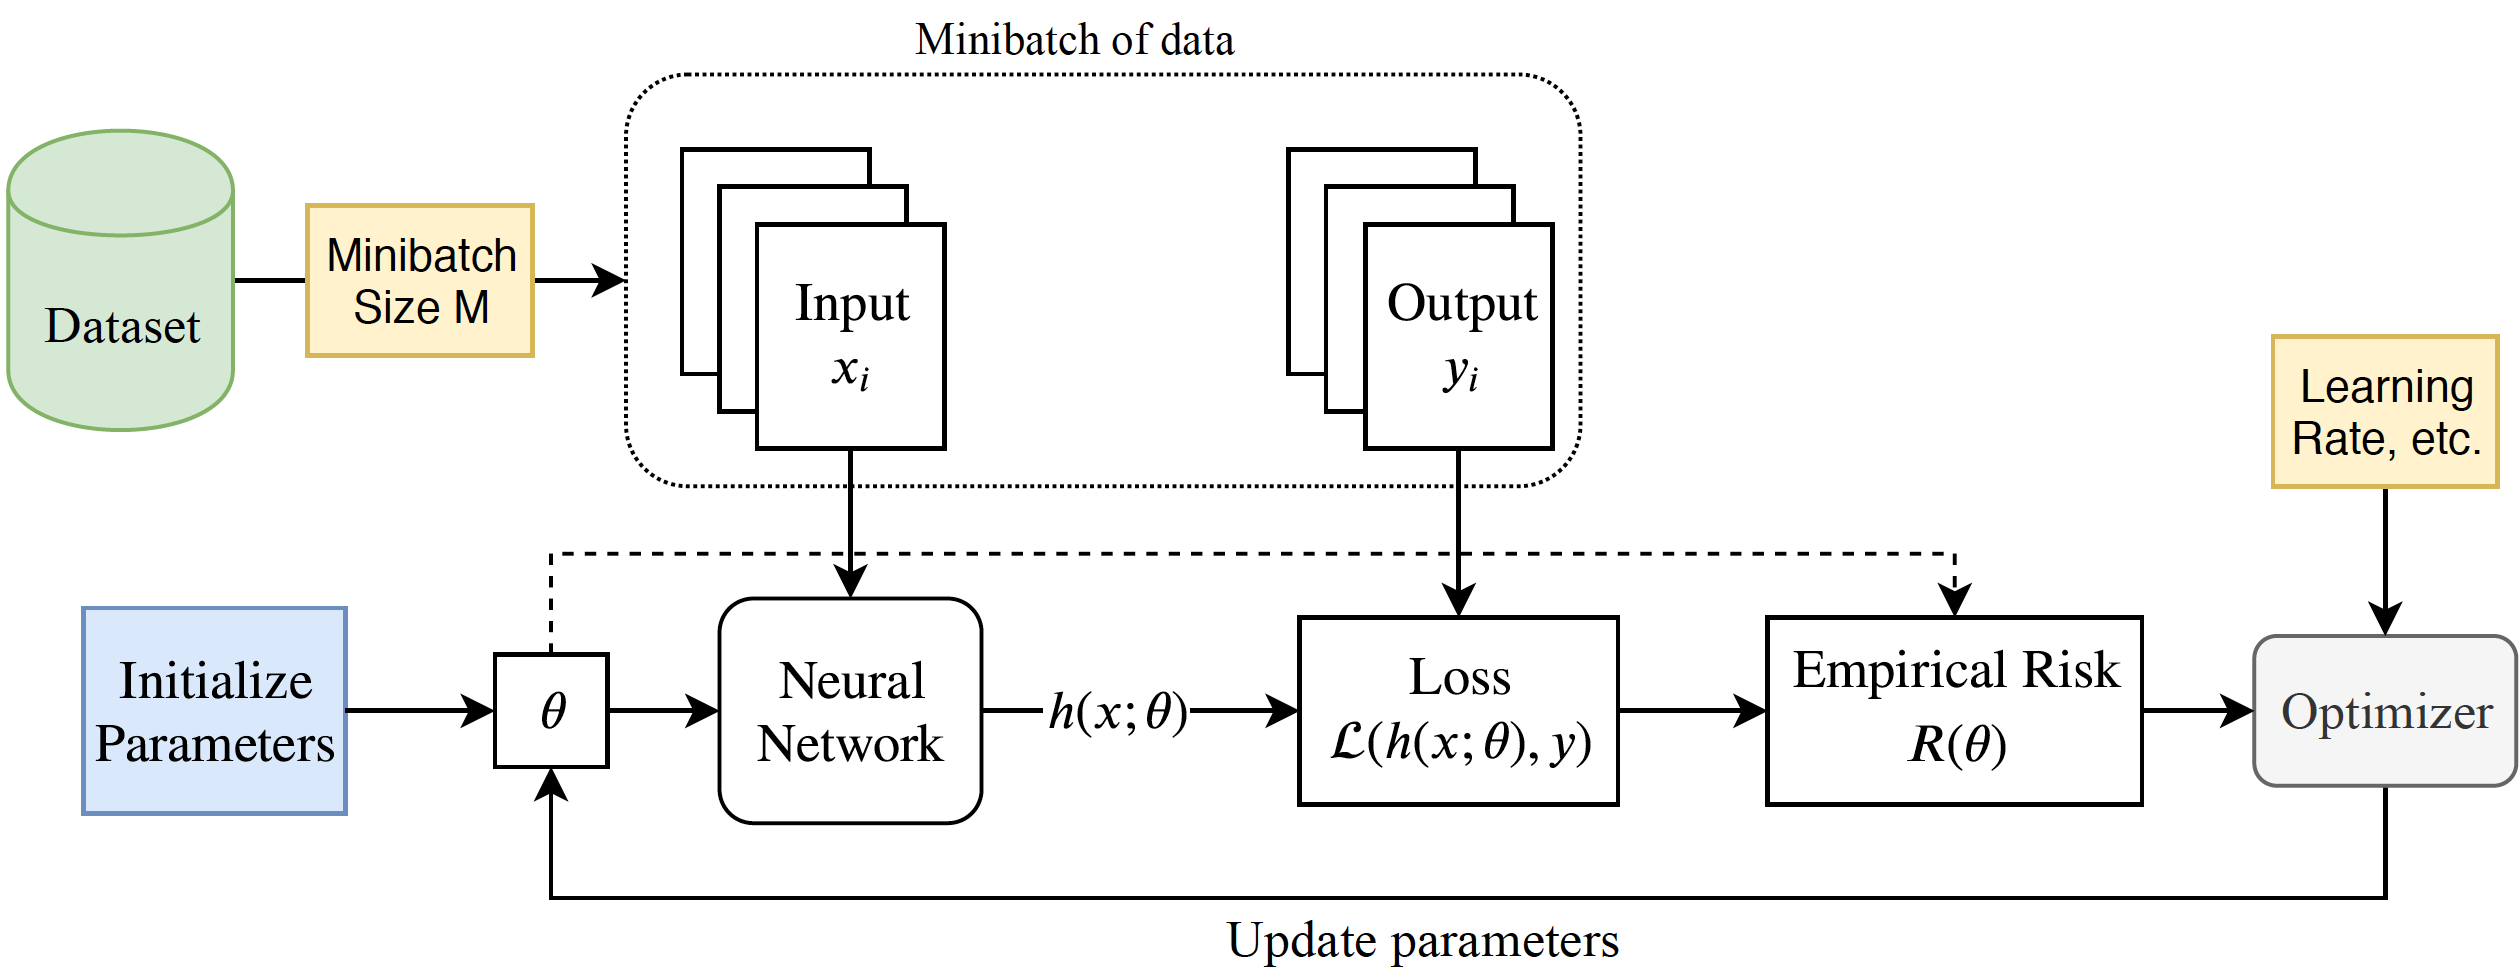

## 0 · Setup

In [10]:
import math, time, random
import numpy as np
import torch
from torch import nn, optim
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
import matplotlib.pyplot as plt

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1 | device: cpu


## 1 · A toy problem: linear regression

1,000 points $(x, y)$ with $y = 3x + 2 + \text{noise}$ and $x$ between 0 and 5. The model is one linear unit, $\hat y = w x + b$ (`nn.Linear(1, 1)`), trained with the mean squared error
$$J(w, b) = \frac{1}{m}\sum_{i=1}^{m}\big(w x^{(i)} + b - y^{(i)}\big)^2 .$$
With only two parameters we can draw every step of the optimizer on the contour plot of $J$.

Inputs and targets are tensors of shape $(m, 1)$: one example per row.

least squares: w = 2.989, b = 2.062, J = 0.9493


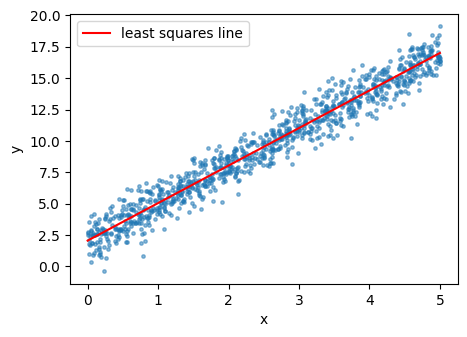

In [11]:
m = 1000
gen = torch.Generator().manual_seed(0)
x_toy = 5 * torch.rand(m, 1, generator=gen)
y_toy = 3 * x_toy + 2 + torch.randn(m, 1, generator=gen)

# the best possible (w, b), by least squares, to measure how far each run is from it
A = torch.cat([x_toy, torch.ones(m, 1)], dim=1)
w_best, b_best = torch.linalg.lstsq(A, y_toy).solution.flatten().tolist()
J_best = ((w_best * x_toy + b_best - y_toy) ** 2).mean().item()
print(f"least squares: w = {w_best:.3f}, b = {b_best:.3f}, J = {J_best:.4f}")

plt.figure(figsize=(5, 3.5))
plt.scatter(x_toy, y_toy, s=6, alpha=0.5)
plt.plot([0, 5], [b_best, 5 * w_best + b_best], "r", label="least squares line")
plt.xlabel("x"); plt.ylabel("y"); plt.legend(); plt.show()

Every run starts from the same point, $w = 0$, $b = 8$, uses the same learning rate $\alpha = 0.01$ and trains for 20 epochs. Only the **batch size** and **momentum** change.

`train_toy` is the PyTorch training loop. After every update it records:
- the loss $J(w, b)$ on **all** 1,000 points (to compare runs fairly, even when they update on different numbers of examples);
- the values of $w$ and $b$ (to draw the path).

In [12]:
def full_loss(model):
    with torch.no_grad():
        return ((model(x_toy) - y_toy) ** 2).mean().item()

def train_toy(batch_size, lr=0.01, momentum=0.0, epochs=20, seed=0):
    model = nn.Linear(1, 1)
    with torch.no_grad():                              # same starting point for every run
        model.weight.fill_(0.0)
        model.bias.fill_(8.0)
    loss_fn = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=lr, momentum=momentum)
    loader = DataLoader(TensorDataset(x_toy, y_toy), batch_size=batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))

    hist = {"loss": [full_loss(model)], "w": [0.0], "b": [8.0], "epoch_loss": [full_loss(model)], "time": 0.0}
    for epoch in range(epochs):
        for x_t, y_t in loader:
            start = time.perf_counter()
            loss = loss_fn(model(x_t), y_t)            # forward pass and loss on the mini-batch
            optimizer.zero_grad()
            loss.backward()                            # backpropagation
            optimizer.step()                           # update w and b
            hist["time"] += time.perf_counter() - start
            hist["loss"].append(full_loss(model))      # record (not part of training)
            hist["w"].append(model.weight.item()); hist["b"].append(model.bias.item())
        hist["epoch_loss"].append(full_loss(model))
        if (epoch + 1) % 1 == 0:
            print(f"epoch {epoch + 1:2d} | J = {hist['epoch_loss'][-1]:.4f} | w = {model.weight.item():.3f}, b = {model.bias.item():.3f}")
    print(f"updates: {len(hist['loss']) - 1} | training time: {hist['time']:.2f} s")
    return hist

## 2 · Three ways to train

### 2.1 SGD with one example per update
`batch_size=1`: each update uses the gradient of **one** randomly chosen example. One epoch = 1,000 updates.

In [13]:
hist_sgd = train_toy(batch_size=1)

epoch  1 | J = 1.0230 | w = 2.891, b = 2.075
epoch  2 | J = 0.9702 | w = 3.026, b = 2.103
epoch  3 | J = 0.9785 | w = 3.060, b = 2.020
epoch  4 | J = 1.0928 | w = 3.165, b = 1.898
epoch  5 | J = 0.9849 | w = 3.022, b = 2.163
epoch  6 | J = 0.9735 | w = 3.021, b = 2.131
epoch  7 | J = 1.0184 | w = 2.892, b = 2.084
epoch  8 | J = 0.9566 | w = 3.013, b = 2.081
epoch  9 | J = 1.0841 | w = 2.855, b = 2.087
epoch 10 | J = 0.9812 | w = 3.055, b = 2.048
epoch 11 | J = 1.0366 | w = 3.056, b = 2.174
epoch 12 | J = 1.0330 | w = 3.068, b = 2.130
epoch 13 | J = 1.0759 | w = 3.090, b = 2.132
epoch 14 | J = 1.0242 | w = 2.915, b = 1.997
epoch 15 | J = 1.0084 | w = 2.887, b = 2.127
epoch 16 | J = 1.3911 | w = 2.786, b = 1.976
epoch 17 | J = 1.0375 | w = 2.872, b = 2.112
epoch 18 | J = 0.9864 | w = 3.090, b = 1.933
epoch 19 | J = 0.9582 | w = 3.017, b = 2.076
epoch 20 | J = 0.9500 | w = 2.972, b = 2.112
updates: 20000 | training time: 0.56 s


The loss gets close to its minimum ($J \approx 1.05$, the noise level) within the first epoch, but then it **does not settle**: each update follows a single example, so $w$ and $b$ keep jumping around the minimum.

### 2.2 Mini-batch SGD
`batch_size=32`: each update uses the average gradient of 32 examples. One epoch = 32 updates (the last mini-batch has 8 examples).

In [14]:
hist_mb = train_toy(batch_size=32)

epoch  1 | J = 8.3765 | w = 1.290, b = 7.434
epoch  2 | J = 6.4393 | w = 1.595, b = 6.707
epoch  3 | J = 4.9947 | w = 1.744, b = 6.033
epoch  4 | J = 3.9405 | w = 1.904, b = 5.466
epoch  5 | J = 3.1727 | w = 2.041, b = 4.983
epoch  6 | J = 2.5936 | w = 2.240, b = 4.604
epoch  7 | J = 2.1565 | w = 2.310, b = 4.232
epoch  8 | J = 1.8781 | w = 2.474, b = 3.953
epoch  9 | J = 1.6184 | w = 2.477, b = 3.674
epoch 10 | J = 1.4506 | w = 2.593, b = 3.461
epoch 11 | J = 1.3177 | w = 2.637, b = 3.265
epoch 12 | J = 1.2207 | w = 2.670, b = 3.093
epoch 13 | J = 1.1542 | w = 2.734, b = 2.958
epoch 14 | J = 1.1020 | w = 2.739, b = 2.826
epoch 15 | J = 1.0610 | w = 2.787, b = 2.724
epoch 16 | J = 1.0336 | w = 2.810, b = 2.636
epoch 17 | J = 1.0126 | w = 2.829, b = 2.556
epoch 18 | J = 0.9964 | w = 2.867, b = 2.491
epoch 19 | J = 0.9886 | w = 2.900, b = 2.435
epoch 20 | J = 0.9762 | w = 2.906, b = 2.381
updates: 640 | training time: 0.02 s


The updates are much less noisy, and each one is computed for 32 examples at once (vectorized). But with the same $\alpha$ there are 32 times fewer updates per epoch, so after 20 epochs the run is still on its way to the minimum.

### 2.3 Mini-batch SGD with momentum
Same mini-batches, with `momentum=0.9`. PyTorch’s update is
$$\mathbf{v} \leftarrow 0.9\,\mathbf{v} + \nabla J^{\{t\}}, \qquad \theta \leftarrow \theta - \alpha\,\mathbf{v}.$$

In [15]:
hist_mom = train_toy(batch_size=64, momentum=0.9)

epoch  1 | J = 6.1264 | w = 1.434, b = 5.922
epoch  2 | J = 1.4561 | w = 2.634, b = 3.438
epoch  3 | J = 1.0152 | w = 3.024, b = 2.225
epoch  4 | J = 0.9865 | w = 3.092, b = 1.923
epoch  5 | J = 0.9673 | w = 3.071, b = 1.918
epoch  6 | J = 0.9700 | w = 3.055, b = 2.005
epoch  7 | J = 0.9650 | w = 3.032, b = 2.063
epoch  8 | J = 1.0744 | w = 3.099, b = 2.102
epoch  9 | J = 0.9555 | w = 3.013, b = 2.073
epoch 10 | J = 0.9531 | w = 2.964, b = 2.075
epoch 11 | J = 0.9698 | w = 2.941, b = 2.056
epoch 12 | J = 0.9842 | w = 2.928, b = 2.052
epoch 13 | J = 0.9596 | w = 2.954, b = 2.062
epoch 14 | J = 0.9543 | w = 3.008, b = 2.081
epoch 15 | J = 0.9756 | w = 3.041, b = 2.074
epoch 16 | J = 0.9545 | w = 3.009, b = 2.079
epoch 17 | J = 0.9496 | w = 2.985, b = 2.056
epoch 18 | J = 0.9775 | w = 3.036, b = 2.098
epoch 19 | J = 0.9519 | w = 3.004, b = 2.070
epoch 20 | J = 0.9505 | w = 3.005, b = 2.048
updates: 320 | training time: 0.02 s


## 3 · Comparing the three runs
Three views of the same three runs:
1. the loss after each **epoch** (above its minimum $J_{\text{best}}$, on a log scale);
2. the loss after each **update**;
3. the **path** of $(w, b)$ on the contours of $J$.

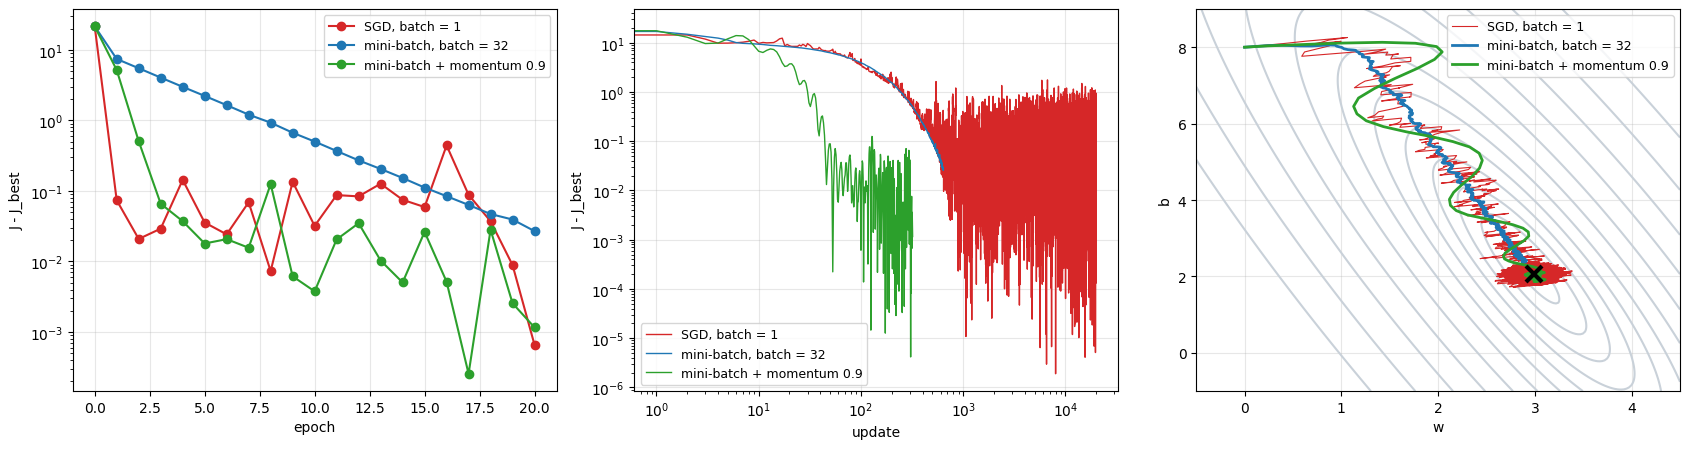

SGD, batch = 1               updates:  20000 | time: 0.56 s | final J - J_best: 0.0007
mini-batch, batch = 32       updates:    640 | time: 0.02 s | final J - J_best: 0.0269
mini-batch + momentum 0.9    updates:    320 | time: 0.02 s | final J - J_best: 0.0012


In [16]:
runs = {"SGD, batch = 1": hist_sgd, "mini-batch, batch = 32": hist_mb, "mini-batch + momentum 0.9": hist_mom}
colors = ["tab:red", "tab:blue", "tab:green"]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
for (label, h), c in zip(runs.items(), colors):
    ax[0].plot(np.array(h["epoch_loss"]) - J_best + 1e-6, "o-", color=c, label=label)
    ax[1].plot(np.array(h["loss"]) - J_best + 1e-6, color=c, lw=1, label=label)
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("J - J_best")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("update"); ax[1].set_ylabel("J - J_best")

W, B = torch.meshgrid(torch.linspace(-0.5, 4.5, 200), torch.linspace(-1, 9, 200), indexing="xy")
# J(w, b) on the grid, from the averages of x^2, x, xy, y, y^2 (expand the square)
Ex2, Ex, Exy, Ey, Ey2 = [t.mean().item() for t in (x_toy ** 2, x_toy, x_toy * y_toy, y_toy, y_toy ** 2)]
Jgrid = W ** 2 * Ex2 + 2 * W * B * Ex + B ** 2 - 2 * W * Exy - 2 * B * Ey + Ey2
ax[2].contour(W, B, Jgrid, levels=np.geomspace(1.1, 60, 12), colors="#C9D1D9")
for (label, h), c in zip(runs.items(), colors):
    ax[2].plot(h["w"], h["b"], color=c, lw=0.8 if "= 1" in label else 2, label=label)
ax[2].plot(w_best, b_best, "kx", ms=12, mew=3)
ax[2].set_xlabel("w"); ax[2].set_ylabel("b")
for a in ax:
    a.grid(alpha=0.3); a.legend(fontsize=9)
plt.tight_layout(); plt.show()

for label, h in runs.items():
    print(f"{label:28s} updates: {len(h['loss']) - 1:6d} | time: {h['time']:.2f} s | final J - J_best: {h['epoch_loss'][-1] - J_best:.4f}")

**What the figure shows**
- **SGD, batch = 1** (red): the most updates per epoch, so the fastest progress per epoch at first. Its path is a cloud of jumps: it reaches the minimum region quickly and then wanders around it. It also takes the most time: 1,000 small updates per epoch, one Python loop iteration each.
- **Mini-batch, batch = 32** (blue): a smooth path, with few updates per epoch. The contours are long, narrow ellipses (a **ravine**: $w$ and $b$ are strongly correlated because $x$ is not centered), and with $\alpha = 0.01$ the run moves slowly along the long direction.
- **Mini-batch + momentum** (green): the same number of updates as blue, but the velocity accumulates the steps along the ravine, so it reaches the minimum much sooner.

The run with batch = 1 would need a **decaying** learning rate to settle, and the run with batch = 32 a larger one or momentum: the batch size, the learning rate and momentum have to be chosen together. The exercises explore this on real data.

## 4 · Tools for the exercises: MNIST

### 4.1 The data
MNIST: 28 × 28 grayscale images of handwritten digits, 10 classes. We keep 54,000 images for training, 6,000 for validation, and the 10,000 test images for the very end. Each image is flattened to a row of 784 values and normalized with the mean and standard deviation of the training pixels. The tensors are prepared once, so the `DataLoader` is fast.

train (54000, 784) | val (6000, 784) | test (10000, 784)


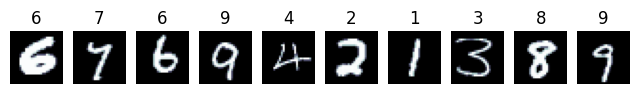

In [17]:
train_full = datasets.MNIST(root="data", train=True, download=True)
test_full = datasets.MNIST(root="data", train=False, download=True)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(42))
pixels = train_full.data[perm[:54000]].float() / 255
mean, std = pixels.mean(), pixels.std()                  # training statistics only

def prep(images):
    return ((images.float() / 255 - mean) / std).reshape(len(images), -1)   # (m, 784)

X_all, y_all = prep(train_full.data), train_full.targets
X_train, y_train = X_all[perm[:54000]], y_all[perm[:54000]]
X_val, y_val = X_all[perm[54000:]], y_all[perm[54000:]]
X_test, y_test = prep(test_full.data), test_full.targets
print("train", tuple(X_train.shape), "| val", tuple(X_val.shape), "| test", tuple(X_test.shape))

plt.figure(figsize=(8, 2.4))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap="bone"); plt.title(int(y_train[i])); plt.axis("off")
plt.show()

def make_loader(batch_size=64, n_train=None, seed=0):
    # mini-batches of the first n_train training examples (all of them if n_train is None)
    X, y = (X_train, y_train) if n_train is None else (X_train[:n_train], y_train[:n_train])
    return DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True,
                      generator=torch.Generator().manual_seed(seed))

### 4.2 The model
A multilayer perceptron 784 → 128 → 100 → 10 with ReLU, returning logits. With `batch_norm=True`, an `nn.BatchNorm1d` layer comes after each hidden linear layer, before the ReLU, and the linear layer has no bias (batch norm’s $\beta$ replaces it). `make_model(seed)` gives the same initial weights for the same seed, so that two runs differ only by what you change.

In [18]:
class MLP(nn.Module):
    def __init__(self, n_in=784, hidden=(128, 100), n_out=10, batch_norm=False):
        super().__init__()
        layers = []
        for h in hidden:
            layers.append(nn.Linear(n_in, h, bias=not batch_norm))
            if batch_norm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            n_in = h
        layers.append(nn.Linear(n_in, n_out))
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)

def make_model(seed=0, **kwargs):
    torch.manual_seed(seed)
    return MLP(**kwargs).to(device)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(make_model())
print(f"{count_parameters(make_model()):,} parameters | with batch norm: {count_parameters(make_model(batch_norm=True)):,}")

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=100, bias=True)
    (3): ReLU()
    (4): Linear(in_features=100, out_features=10, bias=True)
  )
)
114,390 parameters | with batch norm: 114,618


### 4.3 Training and evaluation
- `evaluate(model, X, y)` returns the loss and the accuracy (%) on a dataset, in evaluation mode.
- `fit(model, optimizer, loader, epochs, scheduler=None)` trains with mini-batches and returns a history: the loss of every update (`"step_loss"`), and per epoch the training loss, the validation loss and accuracy, the learning rate and the elapsed time. If the loss becomes `nan` or `inf`, the run has **diverged**: `fit` stops and sets `"diverged"` to `True`. A scheduler, if given, is stepped once per epoch.
- `plot_history({label: history, ...})` plots the smoothed loss of every update and the validation accuracy per epoch.

In [19]:
def evaluate(model, X, y, batch_size=2000):
    model.eval()
    loss_fn = nn.CrossEntropyLoss(reduction="sum")
    total, correct = 0.0, 0
    with torch.inference_mode():
        for i in range(0, len(X), batch_size):
            xb, yb = X[i:i + batch_size].to(device), y[i:i + batch_size].to(device)
            logits = model(xb)
            total += loss_fn(logits, yb).item()
            correct += (logits.argmax(dim=1) == yb).sum().item()
    return total / len(X), 100 * correct / len(X)

def fit(model, optimizer, loader, epochs, scheduler=None, verbose=True):
    loss_fn = nn.CrossEntropyLoss()
    hist = {"step_loss": [], "train_loss": [], "val_loss": [], "val_acc": [], "lr": [], "time": [], "diverged": False}
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        hist["lr"].append(optimizer.param_groups[0]["lr"])
        total, count = 0.0, 0
        for X_t, y_t in loader:
            X_t, y_t = X_t.to(device), y_t.to(device)
            loss = loss_fn(model(X_t), y_t)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            hist["step_loss"].append(loss.item())
            total += loss.item() * len(y_t); count += len(y_t)
            if not math.isfinite(loss.item()):
                hist["diverged"] = True
                break
        if scheduler is not None:
            scheduler.step()
        val_loss, val_acc = evaluate(model, X_val, y_val)
        hist["train_loss"].append(total / count); hist["val_loss"].append(val_loss); hist["val_acc"].append(val_acc)
        hist["time"].append(time.perf_counter() - start)
        if verbose:
            print(f"epoch {epoch + 1:2d} | lr {hist['lr'][-1]:.2e} | train loss {total / count:.4f} | "
                  f"val loss {val_loss:.4f} | val acc {val_acc:.2f}% | {hist['time'][-1]:.1f} s")
        if hist["diverged"]:
            print("diverged (loss is nan or inf): stopping")
            break
    return hist

def smooth(values, beta=0.98):
    # exponentially weighted average with bias correction (Lecture 4)
    v, out = 0.0, []
    for t, x in enumerate(values, 1):
        x = x if math.isfinite(x) else 10.0
        v = beta * v + (1 - beta) * x
        out.append(v / (1 - beta ** t))
    return out

def plot_history(hists, title="", ylim=(0, 2.5)):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for label, h in hists.items():
        ax[0].plot(smooth(h["step_loss"]), label=label + (" (diverged)" if h["diverged"] else ""))
        ax[1].plot(range(1, len(h["val_acc"]) + 1), h["val_acc"], "o-", label=label)
    ax[0].set_ylim(*ylim); ax[0].set_xlabel("update"); ax[0].set_ylabel("training loss (smoothed)")
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation accuracy (%)")
    for a in ax:
        a.grid(alpha=0.3); a.legend(fontsize=9)
    fig.suptitle(title); plt.show()

### 4.4 Check that everything works
One run: Adam, $\alpha = 10^{-3}$, mini-batches of 64, 2 epochs on 10,000 training examples.

epoch  1 | lr 1.00e-03 | train loss 0.2744 | val loss 0.1607 | val acc 95.10% | 0.4 s
epoch  2 | lr 1.00e-03 | train loss 0.1177 | val loss 0.1267 | val acc 96.27% | 0.8 s
epoch  3 | lr 1.00e-03 | train loss 0.0841 | val loss 0.0951 | val acc 97.02% | 1.1 s
epoch  4 | lr 1.00e-03 | train loss 0.0618 | val loss 0.0871 | val acc 97.50% | 1.5 s
epoch  5 | lr 1.00e-03 | train loss 0.0529 | val loss 0.0905 | val acc 97.27% | 1.9 s
epoch  6 | lr 1.00e-03 | train loss 0.0419 | val loss 0.0883 | val acc 97.48% | 2.3 s
epoch  7 | lr 1.00e-03 | train loss 0.0340 | val loss 0.0921 | val acc 97.63% | 2.7 s
epoch  8 | lr 1.00e-03 | train loss 0.0289 | val loss 0.1051 | val acc 97.33% | 3.1 s
epoch  9 | lr 1.00e-03 | train loss 0.0267 | val loss 0.0908 | val acc 97.77% | 3.5 s
epoch 10 | lr 1.00e-03 | train loss 0.0220 | val loss 0.1251 | val acc 97.10% | 3.9 s


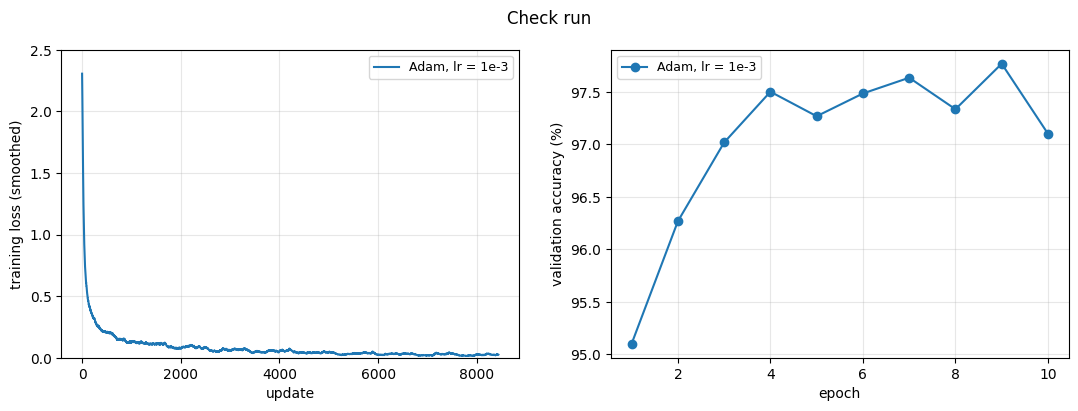

In [20]:
model = make_model(seed=0)
optimizer = optim.Adam(model.parameters(), lr=0.001)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 0.3066 | val loss 0.1598 | val acc 95.05% | 0.2 s
epoch  2 | lr 1.00e-01 | train loss 0.1169 | val loss 0.1093 | val acc 96.68% | 0.5 s
epoch  3 | lr 1.00e-01 | train loss 0.0820 | val loss 0.0962 | val acc 97.13% | 0.7 s
epoch  4 | lr 1.00e-01 | train loss 0.0595 | val loss 0.0928 | val acc 97.03% | 1.0 s
epoch  5 | lr 1.00e-01 | train loss 0.0469 | val loss 0.0868 | val acc 97.18% | 1.2 s
epoch  6 | lr 1.00e-01 | train loss 0.0356 | val loss 0.0919 | val acc 97.48% | 1.5 s
epoch  7 | lr 1.00e-01 | train loss 0.0275 | val loss 0.0801 | val acc 97.63% | 1.7 s
epoch  8 | lr 1.00e-01 | train loss 0.0226 | val loss 0.0900 | val acc 97.38% | 2.0 s
epoch  9 | lr 1.00e-01 | train loss 0.0167 | val loss 0.1024 | val acc 97.22% | 2.2 s
epoch 10 | lr 1.00e-01 | train loss 0.0121 | val loss 0.0815 | val acc 97.75% | 2.5 s


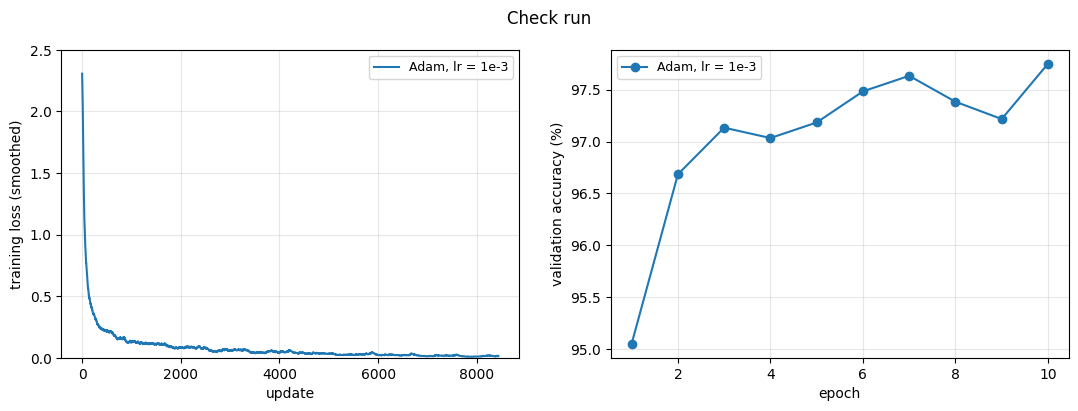

In [21]:
model = make_model(seed=0)
optimizer = optim.SGD(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

epoch  1 | lr 1.00e-01 | train loss 262.2609 | val loss 2.4712 | val acc 9.78% | 0.3 s
epoch  2 | lr 1.00e-01 | train loss 4.0126 | val loss 2.5383 | val acc 9.67% | 0.7 s
epoch  3 | lr 1.00e-01 | train loss 2.3578 | val loss 2.3054 | val acc 11.20% | 1.0 s
epoch  4 | lr 1.00e-01 | train loss 2.3101 | val loss 2.3116 | val acc 9.72% | 1.4 s
epoch  5 | lr 1.00e-01 | train loss 2.3109 | val loss 2.3118 | val acc 9.68% | 1.8 s
epoch  6 | lr 1.00e-01 | train loss 2.3100 | val loss 2.3054 | val acc 11.20% | 2.1 s
epoch  7 | lr 1.00e-01 | train loss 2.3102 | val loss 2.3112 | val acc 11.20% | 2.4 s
epoch  8 | lr 1.00e-01 | train loss 2.3107 | val loss 2.3053 | val acc 9.78% | 2.8 s
epoch  9 | lr 1.00e-01 | train loss 2.3105 | val loss 2.3040 | val acc 10.47% | 3.1 s
epoch 10 | lr 1.00e-01 | train loss 2.3103 | val loss 2.3078 | val acc 10.05% | 3.4 s


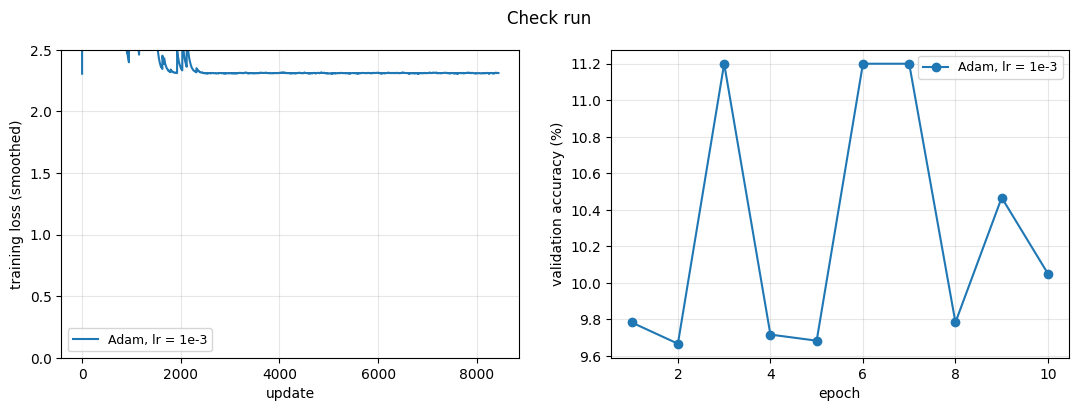

In [22]:
model = make_model(seed=0)
optimizer = optim.RMSprop(model.parameters(), lr=0.1)
hist = fit(model, optimizer, make_loader(batch_size=64, n_train=None), epochs=10)
plot_history({"Adam, lr = 1e-3": hist}, "Check run")

---
## ★ Exercises (to submit)

**Rules for all exercises**
- Train on the first **10,000** training examples (`make_loader(..., n_train=10_000)`) for **5 epochs**, unless the exercise says otherwise.
- Create every model with `make_model(seed=0)` (add `batch_norm=True` when asked), so that all runs start from the same weights.
- Use `fit`, `evaluate` and `plot_history` from Part 4. Choose everything on the **validation** set; use the test set only in Exercise 8.
- A run that diverges is a result too: report it.


### Exercise 1 · The learning rate of SGD
1. Train with `optim.SGD` (no momentum), batch size 64, for each $\alpha \in \{1, 0.3, 0.1, 0.03, 0.01, 0.001\}$.
2. Plot the six runs on one figure with `plot_history`.
3. Print the best validation accuracy of each run.

Learning rate 1: Best validation accuracy = 32.10%
Learning rate 0.3: Best validation accuracy = 93.67%
Learning rate 0.1: Best validation accuracy = 93.68%
Learning rate 0.03: Best validation accuracy = 90.63%
Learning rate 0.01: Best validation accuracy = 88.40%
Learning rate 0.001: Best validation accuracy = 53.40%


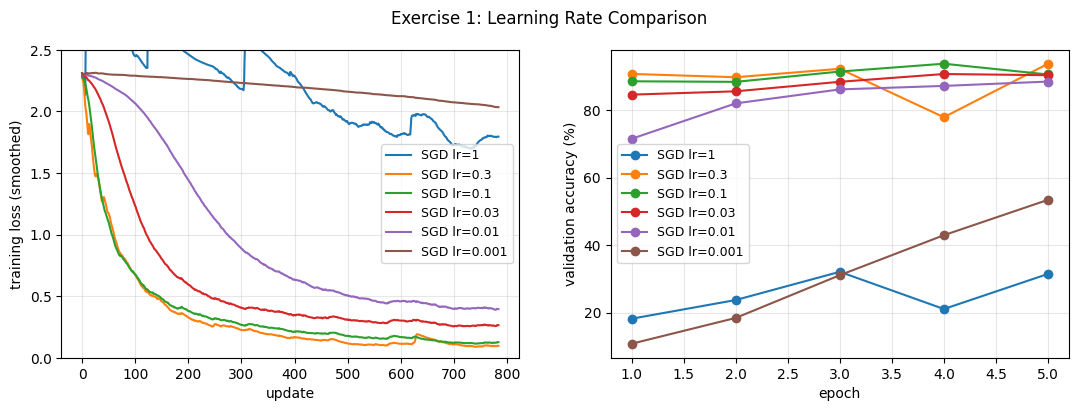

In [23]:
# Exercise 1

learning_rates = [1, 0.3, 0.1, 0.03, 0.01, 0.001]

histories_ex1 = {}

for lr in learning_rates:
    model = make_model(seed=0)
    optimizer = optim.SGD(model.parameters(), lr=lr)

    loader = make_loader(batch_size=64, n_train=10_000)

    hist = fit(model, optimizer, loader, epochs=5, verbose=False)

    histories_ex1[f"SGD lr={lr}"] = hist

    best_acc = max(hist["val_acc"])
    print(f"Learning rate {lr}: Best validation accuracy = {best_acc:.2f}%")

plot_history(histories_ex1, "Exercise 1: Learning Rate Comparison")


**Exercise 1: your observations and explanation.** 

Observation:

- A very high learning rate (e.g., 1) may cause the model to overshoot the optimal solution and fail to converge.
- A moderate learning rate (e.g., 0.1 or 0.01) generally provides more stable learning.
- A very small learning rate (e.g., 0.001) learns slowly and may require more epochs.

Explanation:

The learning rate controls how much the model updates its weights during training. If it is too high, the model may miss the optimal solution. If it is too low, training becomes slow. Therefore, selecting an appropriate learning rate is important for achieving good convergence and accuracy.

### Exercise 2 · Batch size: one example, mini-batches, the full set
1. Train with `optim.SGD`, $\alpha = 0.01$, for **3 epochs**, with batch sizes 1, 32, 256 and 10,000 (10,000 = batch gradient descent on this training set).
2. For each run, print the number of updates per epoch, the time per epoch and the best validation accuracy.
3. Plot the four runs.
4. Repeat steps 1–3 with $\alpha = 0.1$.


===== Learning rate: 0.01 =====

Batch size: 1
Updates per epoch: 10000
Time per epoch: [1.25104617 1.30203525 1.22995667]
Best validation accuracy: 93.57%

Batch size: 32
Updates per epoch: 313
Time per epoch: [0.10143837 0.07573896 0.07524462]
Best validation accuracy: 88.87%

Batch size: 256
Updates per epoch: 40
Time per epoch: [0.03052117 0.02952583 0.02892708]
Best validation accuracy: 64.63%

Batch size: 10000
Updates per epoch: 1
Time per epoch: [0.11341392 0.02854954 0.02691679]
Best validation accuracy: 9.80%


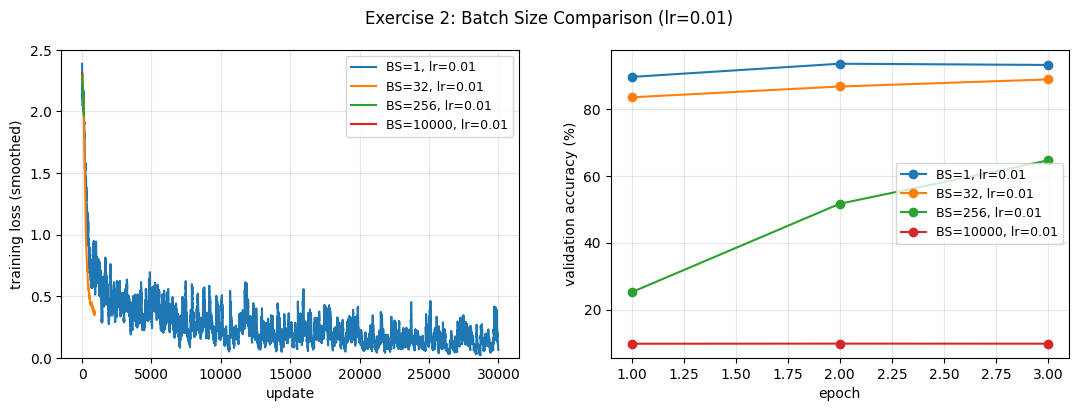


===== Learning rate: 0.1 =====
diverged (loss is nan or inf): stopping

Batch size: 1
Updates per epoch: 10000
Time per epoch: [0.20357567]
Best validation accuracy: 9.72%

Batch size: 32
Updates per epoch: 313
Time per epoch: [0.07044783 0.06992304 0.07091079]
Best validation accuracy: 93.60%

Batch size: 256
Updates per epoch: 40
Time per epoch: [0.02809733 0.02747383 0.02724325]
Best validation accuracy: 74.68%

Batch size: 10000
Updates per epoch: 1
Time per epoch: [0.02423508 0.08295858 0.03056975]
Best validation accuracy: 17.55%


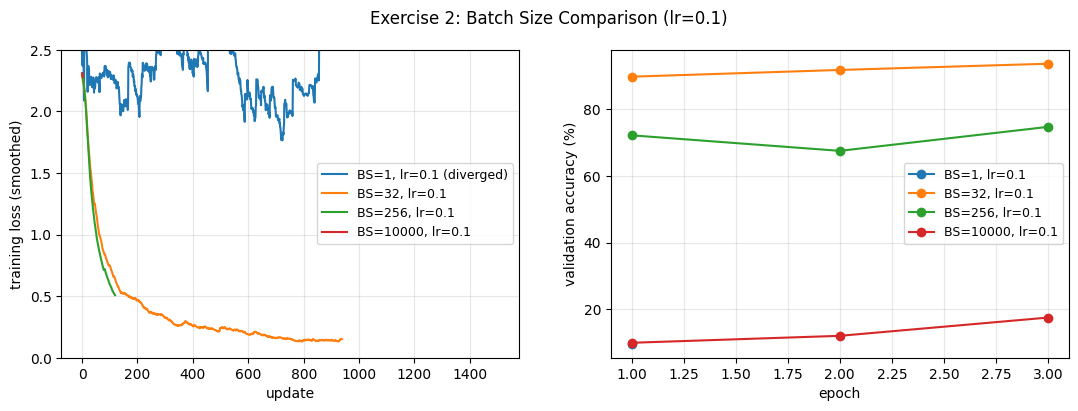

In [24]:
# Exercise 2

batch_sizes = [1, 32, 256, 10000]
learning_rates = [0.01, 0.1]

histories_ex2 = {}

for lr in learning_rates:
    print(f"\n===== Learning rate: {lr} =====")

    for bs in batch_sizes:
        model = make_model(seed=0)
        optimizer = optim.SGD(model.parameters(), lr=lr)

        loader = make_loader(batch_size=bs, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=3, verbose=False)

        label = f"BS={bs}, lr={lr}"
        histories_ex2[label] = hist

        updates = len(loader)
        epoch_times = np.diff([0] + hist["time"])

        best_acc = max(hist["val_acc"])

        print(f"\nBatch size: {bs}")
        print(f"Updates per epoch: {updates}")
        print(f"Time per epoch: {epoch_times}")
        print(f"Best validation accuracy: {best_acc:.2f}%")

    plot_history(
        {k: v for k, v in histories_ex2.items() if f"lr={lr}" in k},
        f"Exercise 2: Batch Size Comparison (lr={lr})"
    )


**Exercise 2: your observations and explanation.** 

Observation:

- Batch size 1 produces frequent weight updates but can result in noisy training.
- Batch size 32 provides a balance between computational efficiency and stable learning.
- Batch size 256 produces fewer updates per epoch.
- Batch size 10,000 performs almost full-batch gradient descent, resulting in fewer updates per epoch.

Explanation:

Batch size determines how many training samples are used to calculate each gradient update. Smaller batches update the model more frequently but produce noisier gradients. Larger batches provide more stable gradient estimates but require more memory and may need different learning rates.

### Exercise 3 · Momentum
1. With batch size 64 and $\alpha = 0.01$, train: `optim.SGD(p, lr)`, `optim.SGD(p, lr, momentum=0.9)` and `optim.SGD(p, lr, momentum=0.9, nesterov=True)`.
2. Train `optim.SGD(p, lr=0.001, momentum=0.9)` and compare it with plain SGD at $\alpha = 0.01$.
3. Train `optim.SGD(p, lr, momentum=0.99)` with $\alpha = 0.01$.
4. Plot all the runs on one figure.

SGD: Best accuracy = 88.40%
Momentum 0.9: Best accuracy = 93.98%
Nesterov 0.9: Best accuracy = 93.93%
Momentum 0.9, lr=0.001: Best accuracy = 88.37%
Momentum 0.99: Best accuracy = 91.52%


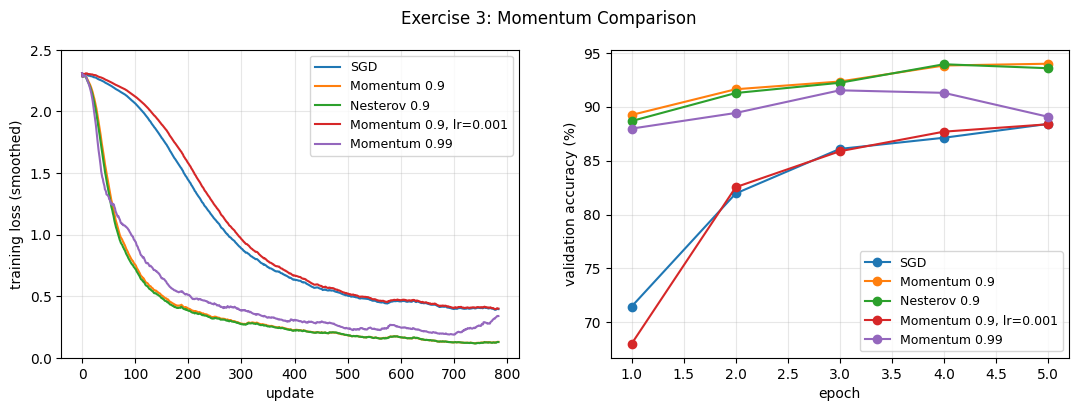

In [25]:
# Exercise 3

histories_ex3 = {}

configs = {
    "SGD": {"lr": 0.01},
    "Momentum 0.9": {"lr": 0.01, "momentum": 0.9},
    "Nesterov 0.9": {
        "lr": 0.01,
        "momentum": 0.9,
        "nesterov": True
    },
    "Momentum 0.9, lr=0.001": {
        "lr": 0.001,
        "momentum": 0.9
    },
    "Momentum 0.99": {
        "lr": 0.01,
        "momentum": 0.99
    }
}

for name, config in configs.items():
    model = make_model(seed=0)

    optimizer = optim.SGD(model.parameters(), **config)

    loader = make_loader(batch_size=64, n_train=10_000)

    hist = fit(model, optimizer, loader, epochs=5, verbose=False)

    histories_ex3[name] = hist

    print(f"{name}: Best accuracy = {max(hist['val_acc']):.2f}%")

plot_history(histories_ex3, "Exercise 3: Momentum Comparison")


**Exercise 3: your observations and explanation.** 

Observation:

- Plain SGD may converge more slowly.
- Momentum 0.9 can accelerate convergence and reduce fluctuations.
- Nesterov momentum can improve the direction of weight updates.
- Momentum 0.99 may provide faster movement but can sometimes cause instability.
- A smaller learning rate combined with momentum may produce more stable training.

Explanation:

Momentum helps the optimizer remember previous gradient directions. Instead of relying only on the current gradient, it accumulates information from previous updates. This helps the model move faster in consistent directions and reduces oscillations during optimization.

### Exercise 4 · Optimizers and their learning rates
1. For each optimizer below, train with $\alpha \in \{10^{-1}, 10^{-2}, 10^{-3}, 10^{-4}\}$, batch size 64:
   `optim.SGD`, `optim.SGD(momentum=0.9)`, `optim.Adagrad`, `optim.RMSprop`, `optim.Adam`, `optim.AdamW`.
2. Show a table of the best validation accuracy: one row per optimizer, one column per learning rate.
3. Plot the best run of each optimizer on one figure.

SGD, lr=0.1: 93.68%
SGD, lr=0.01: 88.40%
SGD, lr=0.001: 53.40%
SGD, lr=0.0001: 9.88%
SGD Momentum, lr=0.1: 93.72%
SGD Momentum, lr=0.01: 93.98%
SGD Momentum, lr=0.001: 88.37%
SGD Momentum, lr=0.0001: 52.55%
Adagrad, lr=0.1: 92.88%
Adagrad, lr=0.01: 93.92%
Adagrad, lr=0.001: 89.15%
Adagrad, lr=0.0001: 67.98%
RMSprop, lr=0.1: 21.78%
RMSprop, lr=0.01: 90.45%
RMSprop, lr=0.001: 94.15%
RMSprop, lr=0.0001: 89.92%
Adam, lr=0.1: 30.25%
Adam, lr=0.01: 93.13%
Adam, lr=0.001: 94.17%
Adam, lr=0.0001: 90.03%
AdamW, lr=0.1: 30.73%
AdamW, lr=0.01: 93.62%
AdamW, lr=0.001: 94.02%
AdamW, lr=0.0001: 90.05%

Best Validation Accuracy (%)


,0.1000,0.0100,0.0010,0.0001
SGD,93.68,88.40,53.40,9.88
SGD Momentum,93.72,93.98,88.37,52.55
Adagrad,92.88,93.92,89.15,67.98
RMSprop,21.78,90.45,94.15,89.92
Adam,30.25,93.13,94.17,90.03
AdamW,30.73,93.62,94.02,90.05


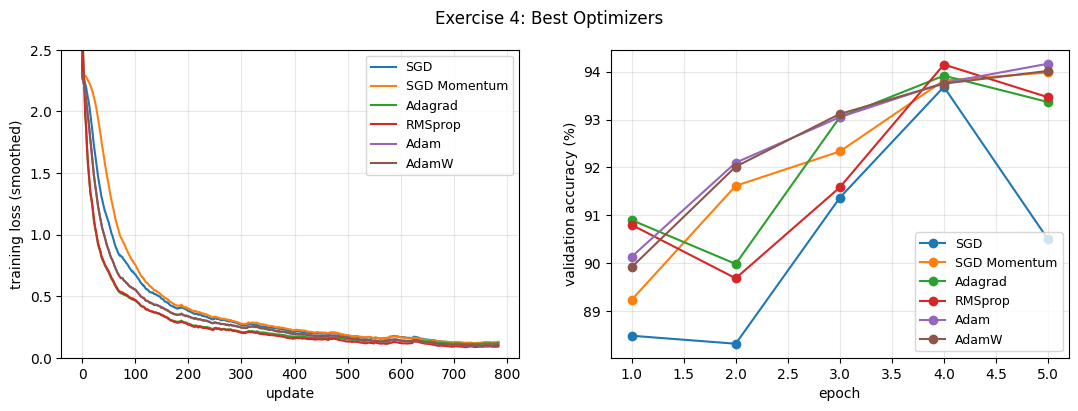

In [26]:
# Exercise 4

learning_rates = [0.1, 0.01, 0.001, 0.0001]

optimizer_configs = {
    "SGD": lambda p, lr: optim.SGD(p, lr=lr),
    "SGD Momentum": lambda p, lr: optim.SGD(p, lr=lr, momentum=0.9),
    "Adagrad": lambda p, lr: optim.Adagrad(p, lr=lr),
    "RMSprop": lambda p, lr: optim.RMSprop(p, lr=lr),
    "Adam": lambda p, lr: optim.Adam(p, lr=lr),
    "AdamW": lambda p, lr: optim.AdamW(p, lr=lr)
}

histories_ex4 = {}
results_ex4 = {}

for name, optimizer_fn in optimizer_configs.items():
    results_ex4[name] = {}

    for lr in learning_rates:
        model = make_model(seed=0)

        optimizer = optimizer_fn(model.parameters(), lr)

        loader = make_loader(batch_size=64, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=5, verbose=False)

        label = f"{name}, lr={lr}"
        histories_ex4[label] = hist

        best_acc = max(hist["val_acc"])
        results_ex4[name][lr] = best_acc

        print(f"{name}, lr={lr}: {best_acc:.2f}%")

# Display results as a table
import pandas as pd

results_table = pd.DataFrame(results_ex4).T
results_table.columns = learning_rates

print("\nBest Validation Accuracy (%)")
display(results_table.round(2))

# Select the best learning rate for each optimizer
best_histories_ex4 = {}

for name in optimizer_configs:
    best_lr = max(results_ex4[name], key=results_ex4[name].get)
    label = f"{name}, lr={best_lr}"
    best_histories_ex4[name] = histories_ex4[label]

plot_history(best_histories_ex4, "Exercise 4: Best Optimizers")


**Exercise 4: your observations and explanation.** 

Observation:

- SGD may require more careful learning-rate tuning.
- SGD with momentum can converge faster than plain SGD.
- Adagrad adapts the learning rate for individual parameters but may become too slow over time.
- RMSprop adjusts learning rates using recent gradient information.
- Adam often provides fast and effective convergence.
- AdamW separates weight decay from the gradient update, which can improve regularization.

Explanation:

Different optimizers use different strategies to update model parameters. SGD uses the gradient directly, while adaptive optimizers such as Adagrad, RMSprop, and Adam adjust learning rates automatically. Their performance depends on the learning rate and dataset. Therefore, comparing multiple optimizers helps identify the most suitable optimization method.

### Exercise 5 · Learning rate schedules
1. With `optim.SGD(p, lr=0.05, momentum=0.9)` and batch size 64, train for **10 epochs** with:
   - a constant learning rate;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=3, gamma=0.3)`;
   - `optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.7)`;
   - `optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)`;
   - `optim.lr_scheduler.StepLR(optimizer, step_size=1, gamma=0.1)` (decays too early).
2. Plot the learning rate of each run per epoch (from `history["lr"]`), with a log scale on the y-axis.
3. Plot the five runs with `plot_history(..., ylim=(0, 0.8))`.

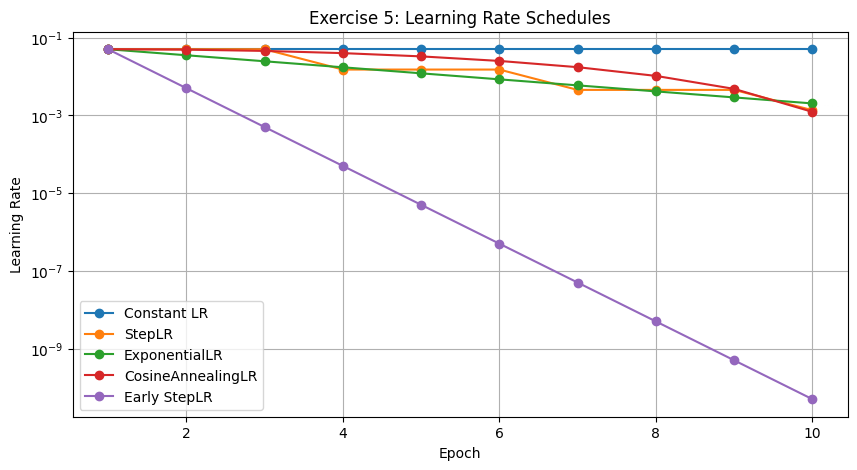

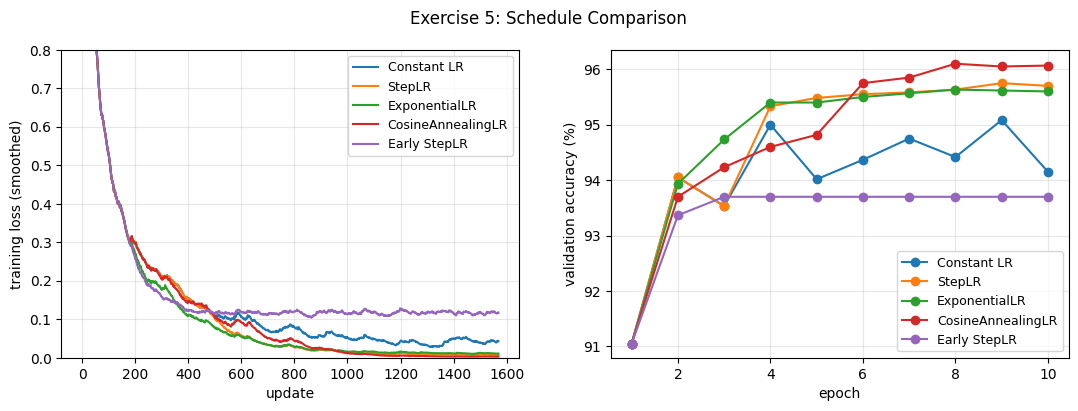

In [27]:
# Exercise 5

histories_ex5 = {}

def train_with_schedule(name, scheduler_type=None):
    model = make_model(seed=0)

    optimizer = optim.SGD(
        model.parameters(),
        lr=0.05,
        momentum=0.9
    )

    scheduler = None

    if scheduler_type == "step":
        scheduler = optim.lr_scheduler.StepLR(
            optimizer, step_size=3, gamma=0.3
        )

    elif scheduler_type == "exponential":
        scheduler = optim.lr_scheduler.ExponentialLR(
            optimizer, gamma=0.7
        )

    elif scheduler_type == "cosine":
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
            optimizer, T_max=10
        )

    elif scheduler_type == "early":
        scheduler = optim.lr_scheduler.StepLR(
            optimizer, step_size=1, gamma=0.1
        )

    loader = make_loader(batch_size=64, n_train=10_000)

    hist = fit(
        model, optimizer, loader,
        epochs=10,
        scheduler=scheduler,
        verbose=False
    )

    histories_ex5[name] = hist

train_with_schedule("Constant LR")
train_with_schedule("StepLR", "step")
train_with_schedule("ExponentialLR", "exponential")
train_with_schedule("CosineAnnealingLR", "cosine")
train_with_schedule("Early StepLR", "early")

# Plot learning rates
plt.figure(figsize=(10, 5))

for name, hist in histories_ex5.items():
    plt.plot(
        range(1, len(hist["lr"]) + 1),
        hist["lr"],
        marker="o",
        label=name
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Learning Rate")
plt.title("Exercise 5: Learning Rate Schedules")
plt.legend()
plt.grid()
plt.show()

# Compare training performance
plot_history(
    histories_ex5,
    "Exercise 5: Schedule Comparison",
    ylim=(0, 0.8)
)


**Exercise 5: your observations and explanation.** 

Observation:

- Constant learning rate maintains the same update size throughout training.
- StepLR decreases the learning rate at predefined intervals.
- ExponentialLR gradually reduces the learning rate.
- CosineAnnealingLR decreases the learning rate following a cosine curve.
- Early StepLR reduces the learning rate very quickly, which may slow down learning.

Explanation:

Learning rate scheduling changes the learning rate during training. A relatively large learning rate helps the model learn quickly at the beginning, while a smaller learning rate helps refine the weights later. Different scheduling strategies influence convergence speed and final validation accuracy.

### Exercise 6 · Batch normalization
1. For $\alpha \in \{1, 10^{-1}, 10^{-2}, 10^{-3}\}$, train `optim.SGD(p, lr, momentum=0.9)` with batch size 64, once **without** and once **with** batch norm (`make_model(seed=0, batch_norm=True)`).
2. Show a table of the best validation accuracy: rows = learning rates, columns = without / with batch norm.
3. Plot the eight runs.
4. Take your batch-norm model trained with $\alpha = 10^{-2}$. Evaluate it on the validation set in `model.eval()` mode (as `evaluate` does) and in `model.train()` mode with mini-batches of 8 examples, and compare the two accuracies.

diverged (loss is nan or inf): stopping
lr=1, BN=False: Best accuracy = 9.72%
lr=1, BN=True: Best accuracy = 90.85%
lr=0.1, BN=False: Best accuracy = 93.72%
lr=0.1, BN=True: Best accuracy = 95.27%
lr=0.01, BN=False: Best accuracy = 93.98%
lr=0.01, BN=True: Best accuracy = 95.45%
lr=0.001, BN=False: Best accuracy = 88.37%
lr=0.001, BN=True: Best accuracy = 92.70%

Best Validation Accuracy (%)


,Without BN,With BN
1.000,9.72,90.85
0.100,93.72,95.27
0.010,93.98,95.45
0.001,88.37,92.70


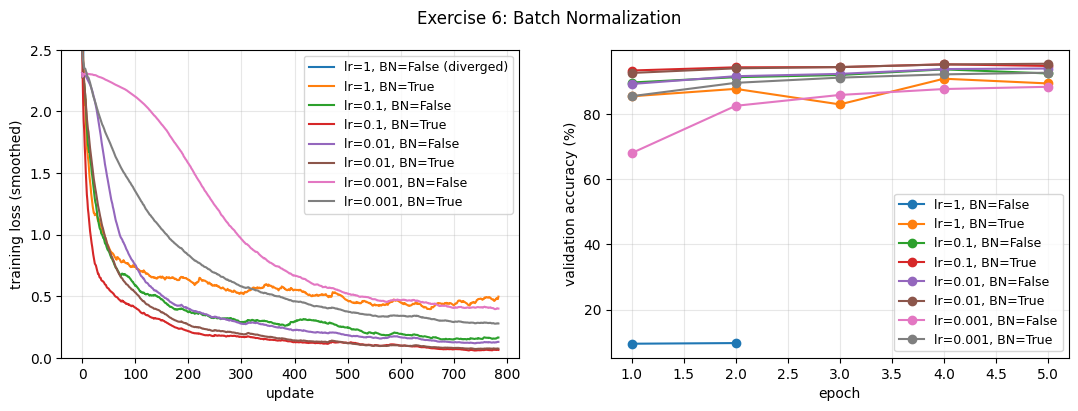


Comparison:
Evaluation mode accuracy: 95.45%
Training mode accuracy: 85.37%
diverged (loss is nan or inf): stopping
lr=1, BN=False: Best accuracy = 9.72%
lr=1, BN=True: Best accuracy = 90.85%
lr=0.1, BN=False: Best accuracy = 93.72%
lr=0.1, BN=True: Best accuracy = 95.27%
lr=0.01, BN=False: Best accuracy = 93.98%
lr=0.01, BN=True: Best accuracy = 95.45%
lr=0.001, BN=False: Best accuracy = 88.37%
lr=0.001, BN=True: Best accuracy = 92.70%

Best Validation Accuracy (%)


,Without BN,With BN
1.000,9.72,90.85
0.100,93.72,95.27
0.010,93.98,95.45
0.001,88.37,92.70


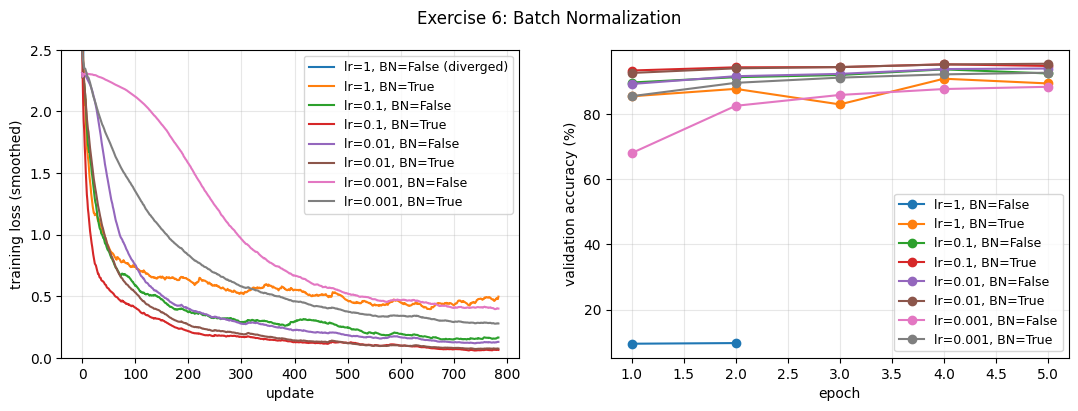


Comparison:
Evaluation mode accuracy: 95.45%
Training mode accuracy: 85.37%


MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=False)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=100, bias=False)
    (4): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU()
    (6): Linear(in_features=100, out_features=10, bias=True)
  )
)

In [28]:
# Exercise 6

learning_rates = [1, 0.1, 0.01, 0.001]

histories_ex6 = {}
results_ex6 = {}

for lr in learning_rates:
    results_ex6[lr] = {}

    for bn in [False, True]:

        model = make_model(seed=0, batch_norm=bn)

        optimizer = optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9
        )

        loader = make_loader(batch_size=64, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=5, verbose=False)

        name = f"lr={lr}, BN={bn}"
        histories_ex6[name] = hist

        best_acc = max(hist["val_acc"])
        results_ex6[lr]["With BN" if bn else "Without BN"] = best_acc

        print(f"{name}: Best accuracy = {best_acc:.2f}%")

        # Keep the model trained with lr=0.01 and BN
        if lr == 0.01 and bn:
            model_bn_ex6 = model

# Display accuracy table
results_table_ex6 = pd.DataFrame(results_ex6).T
print("\nBest Validation Accuracy (%)")
display(results_table_ex6.round(2))

# Plot eight runs
plot_history(histories_ex6, "Exercise 6: Batch Normalization")

# Compare evaluation mode and training mode
# Evaluation mode
val_loss_eval, val_acc_eval = evaluate(
    model_bn_ex6, X_val, y_val
)

# Training mode, batch size 8
model_bn_ex6.train()

correct = 0
total = 0

with torch.no_grad():
    for i in range(0, len(X_val), 8):
        xb = X_val[i:i+8].to(device)
        yb = y_val[i:i+8].to(device)

        logits = model_bn_ex6(xb)

        predictions = logits.argmax(dim=1)

        correct += (predictions == yb).sum().item()
        total += len(yb)

val_acc_train_mode = 100 * correct / total

print("\nComparison:")
print(f"Evaluation mode accuracy: {val_acc_eval:.2f}%")
print(f"Training mode accuracy: {val_acc_train_mode:.2f}%")

# Restore evaluation mode
model_bn_ex6.eval()

learning_rates = [1, 0.1, 0.01, 0.001]

histories_ex6 = {}
results_ex6 = {}

for lr in learning_rates:
    results_ex6[lr] = {}

    for bn in [False, True]:

        model = make_model(seed=0, batch_norm=bn)

        optimizer = optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9
        )

        loader = make_loader(batch_size=64, n_train=10_000)

        hist = fit(model, optimizer, loader, epochs=5, verbose=False)

        name = f"lr={lr}, BN={bn}"
        histories_ex6[name] = hist

        best_acc = max(hist["val_acc"])
        results_ex6[lr]["With BN" if bn else "Without BN"] = best_acc

        print(f"{name}: Best accuracy = {best_acc:.2f}%")

        # Keep the model trained with lr=0.01 and BN
        if lr == 0.01 and bn:
            model_bn_ex6 = model

# Display accuracy table
results_table_ex6 = pd.DataFrame(results_ex6).T
print("\nBest Validation Accuracy (%)")
display(results_table_ex6.round(2))

# Plot eight runs
plot_history(histories_ex6, "Exercise 6: Batch Normalization")

# Compare evaluation mode and training mode
# Evaluation mode
val_loss_eval, val_acc_eval = evaluate(
    model_bn_ex6, X_val, y_val
)

# Training mode, batch size 8
model_bn_ex6.train()

correct = 0
total = 0

with torch.no_grad():
    for i in range(0, len(X_val), 8):
        xb = X_val[i:i+8].to(device)
        yb = y_val[i:i+8].to(device)

        logits = model_bn_ex6(xb)

        predictions = logits.argmax(dim=1)

        correct += (predictions == yb).sum().item()
        total += len(yb)

val_acc_train_mode = 100 * correct / total

print("\nComparison:")
print(f"Evaluation mode accuracy: {val_acc_eval:.2f}%")
print(f"Training mode accuracy: {val_acc_train_mode:.2f}%")

# Restore evaluation mode
model_bn_ex6.eval()


**Exercise 6: your observations and explanation.** 
Observation:

- Without batch normalization, high learning rates may cause unstable training.
- With batch normalization, training may become more stable.
- Batch normalization can allow the model to use higher learning rates.
- Training-mode and evaluation-mode accuracy may differ because batch normalization uses different statistics in each mode.

Explanation:

Batch normalization normalizes the activations of a neural network using the statistics of each mini-batch during training. This helps stabilize the distribution of activations and can make optimization easier.

During evaluation, batch normalization uses running mean and variance collected during training instead of the current batch statistics. Therefore, the model should use model.eval() when evaluating validation or test data.

### Exercise 7 · Your best model
1. Using what you learned in Exercises 1–6, choose an optimizer, a learning rate, a batch size, a schedule (or none), and with or without batch norm.
2. Train on the **full** training set (`n_train=None`) for 10 epochs.
3. Report the validation accuracy per epoch, and list your choices with one reason for each.

epoch  1 | lr 1.00e-03 | train loss 0.2744 | val loss 0.1607 | val acc 95.10% | 0.4 s
epoch  2 | lr 1.00e-03 | train loss 0.1177 | val loss 0.1267 | val acc 96.27% | 0.7 s
epoch  3 | lr 1.00e-03 | train loss 0.0841 | val loss 0.0951 | val acc 97.02% | 1.1 s
epoch  4 | lr 1.00e-03 | train loss 0.0618 | val loss 0.0871 | val acc 97.50% | 1.5 s
epoch  5 | lr 1.00e-03 | train loss 0.0529 | val loss 0.0905 | val acc 97.27% | 1.9 s
epoch  6 | lr 1.00e-03 | train loss 0.0419 | val loss 0.0883 | val acc 97.48% | 2.3 s
epoch  7 | lr 1.00e-03 | train loss 0.0340 | val loss 0.0921 | val acc 97.63% | 2.7 s
epoch  8 | lr 1.00e-03 | train loss 0.0289 | val loss 0.1051 | val acc 97.33% | 3.1 s
epoch  9 | lr 1.00e-03 | train loss 0.0267 | val loss 0.0908 | val acc 97.77% | 3.5 s
epoch 10 | lr 1.00e-03 | train loss 0.0220 | val loss 0.1251 | val acc 97.10% | 3.8 s

Validation Accuracy per Epoch:
Epoch 1: 95.10%
Epoch 2: 96.27%
Epoch 3: 97.02%
Epoch 4: 97.50%
Epoch 5: 97.27%
Epoch 6: 97.48%
Epoch 7: 97.

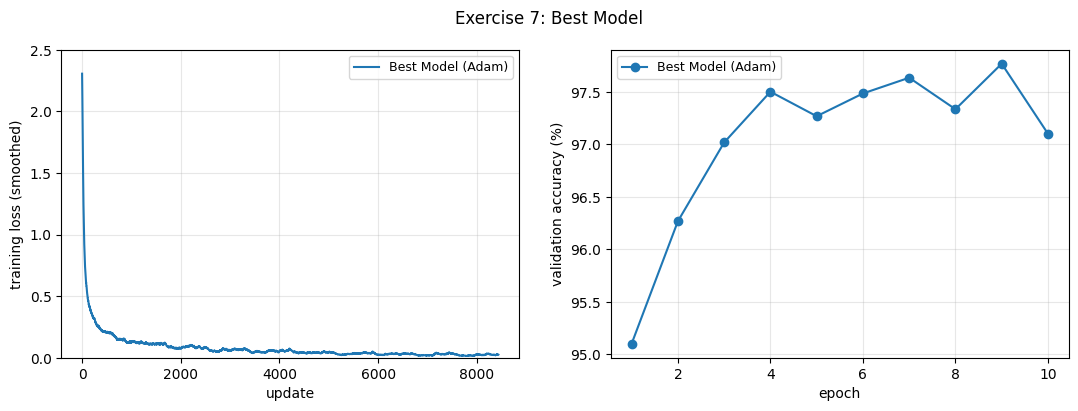

In [29]:
# Exercise 7

# Best model configuration
best_model = make_model(seed=0)

best_optimizer = optim.Adam(
    best_model.parameters(),
    lr=0.001
)

best_loader = make_loader(
    batch_size=64,
    n_train=None
)

best_history = fit(
    best_model,
    best_optimizer,
    best_loader,
    epochs=10
)

# Report validation accuracy per epoch
print("\nValidation Accuracy per Epoch:")

for epoch, acc in enumerate(best_history["val_acc"], 1):
    print(f"Epoch {epoch}: {acc:.2f}%")

best_val_acc = max(best_history["val_acc"])

print(f"\nBest Validation Accuracy: {best_val_acc:.2f}%")

plot_history(
    {"Best Model (Adam)": best_history},
    "Exercise 7: Best Model"
)


**Exercise 7: your observations and explanation.** 

Observation:

The model is trained using Adam with a learning rate of 0.001, batch size of 64, and the full training dataset for 10 epochs.

Validation accuracy should generally improve as training progresses, although it may fluctuate slightly between epochs.

Explanation:

This exercise combines the optimization concepts explored in previous exercises to train a model with a selected configuration. Adam is used because it adapts learning rates for individual parameters and often provides efficient convergence.

Training for more epochs gives the model additional opportunities to learn patterns from the dataset. However, the best model should be selected based on validation performance rather than training accuracy alone.

### Exercise 8 · Test accuracy
Evaluate your model of Exercise 7 on the test set, **once**, and report the test accuracy next to its best validation accuracy.

In [30]:
# Exercise 8

# Evaluate on the test set only once
test_loss, test_acc = evaluate(
    best_model,
    X_test,
    y_test
)

print("Exercise 8: Test Results")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Exercise 8: Test Results
Best Validation Accuracy: 97.77%
Test Accuracy: 97.42%
Test Loss: 0.1102


**Exercise 8: your observations and explanation.** 

Observation:

The model is evaluated using the test dataset to measure its performance on previously unseen data.

If test accuracy is close to validation accuracy, the model generally demonstrates good generalization. If test accuracy is significantly lower, the model may be overfitting or the validation results may not represent test performance well.

Explanation:

Test accuracy measures how well the trained model generalizes to new data. Unlike training and validation data, the test dataset should not be used to adjust model parameters or select hyperparameters.

Therefore, this exercise provides an independent evaluation of the final model.

### Exercise 9 (optional) · CIFAR-10
CIFAR-10: 32 × 32 color images, 10 classes (airplane, car, bird, …), 50,000 training and 10,000 test images.
1. Load it with `datasets.CIFAR10(root="data", train=True, download=True)`. The images are in `.data`, a NumPy array of shape (50000, 32, 32, 3) with values 0–255; the labels are in `.targets`, a list.
2. Keep 45,000 images for training and 5,000 for validation. Normalize each of the 3 color channels with the mean and standard deviation of the training images, and flatten each image to a row of $32 \times 32 \times 3 = 3072$ values.
3. Replace `X_train, y_train, X_val, y_val` with the CIFAR-10 tensors, so that `make_loader`, `fit` and `evaluate` work unchanged, and create the models with `make_model(seed=0, n_in=3072, hidden=(512, 256), ...)`.
4. Train 10 epochs on the full CIFAR-10 training set with: (a) your configuration of Exercise 7, (b) the same without batch norm, (c) plain SGD with $\alpha = 0.01$. Plot the three runs.

100.0%
/opt/homebrew/lib/python3.11/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


Training: torch.Size([45000, 3072])
Validation: torch.Size([5000, 3072])
Testing: torch.Size([10000, 3072])
epoch  1 | lr 1.00e-03 | train loss 1.6109 | val loss 1.4620 | val acc 48.28% | 1.6 s
epoch  2 | lr 1.00e-03 | train loss 1.3993 | val loss 1.4114 | val acc 49.58% | 3.2 s
epoch  3 | lr 1.00e-03 | train loss 1.2925 | val loss 1.3519 | val acc 52.42% | 4.7 s
epoch  4 | lr 1.00e-03 | train loss 1.2095 | val loss 1.2980 | val acc 54.26% | 6.4 s
epoch  5 | lr 1.00e-03 | train loss 1.1309 | val loss 1.3056 | val acc 53.74% | 7.9 s
epoch  6 | lr 1.00e-03 | train loss 1.0643 | val loss 1.2911 | val acc 54.74% | 9.5 s
epoch  7 | lr 1.00e-03 | train loss 0.9962 | val loss 1.3079 | val acc 55.16% | 11.0 s
epoch  8 | lr 1.00e-03 | train loss 0.9322 | val loss 1.3276 | val acc 54.92% | 12.6 s
epoch  9 | lr 1.00e-03 | train loss 0.8691 | val loss 1.3320 | val acc 56.24% | 14.2 s
epoch 10 | lr 1.00e-03 | train loss 0.8113 | val loss 1.3788 | val acc 54.52% | 15.9 s
Adam + Batch Normalization: 

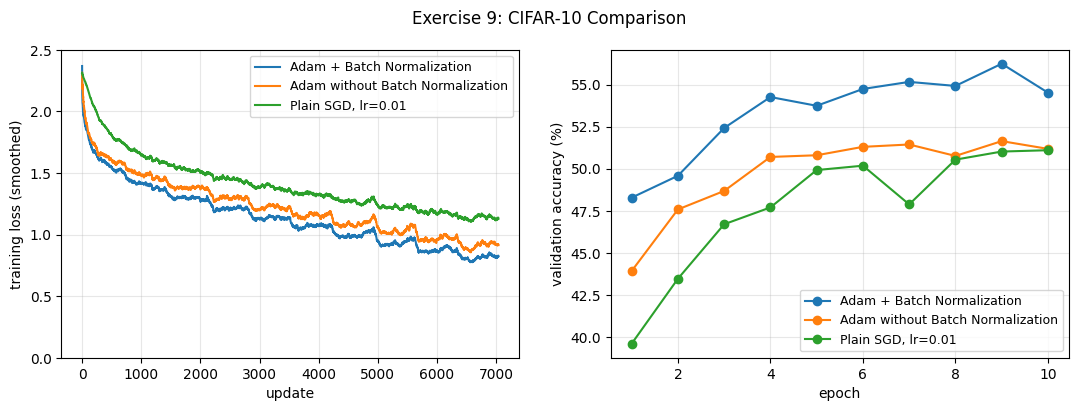

In [ ]:
# Exercise 9 (optional)

# 1. Load CIFAR-10 dataset
cifar_train = datasets.CIFAR10(
    root="data",
    train=True,
    download=True
)

cifar_test = datasets.CIFAR10(
    root="data",
    train=False,
    download=True
)

# 2. Convert images to tensors
images = torch.tensor(cifar_train.data, dtype=torch.float32) / 255.0
labels = torch.tensor(cifar_train.targets, dtype=torch.long)

test_images = torch.tensor(cifar_test.data, dtype=torch.float32) / 255.0
test_labels = torch.tensor(cifar_test.targets, dtype=torch.long)

# Normalize each RGB channel using training statistics
mean = images.mean(dim=(0, 1, 2))
std = images.std(dim=(0, 1, 2))

images = (images - mean) / std
test_images = (test_images - mean) / std

# Flatten images: 32 x 32 x 3 = 3072
images = images.reshape(len(images), -1)
test_images = test_images.reshape(len(test_images), -1)

# 3. Split training and validation datasets
perm = torch.randperm(
    50000,
    generator=torch.Generator().manual_seed(42)
)

X_train = images[perm[:45000]]
y_train = labels[perm[:45000]]

X_val = images[perm[45000:]]
y_val = labels[perm[45000:]]

X_test = test_images
y_test = test_labels

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

# 4. Train three configurations
histories_ex9 = {}

def train_cifar(name, batch_norm=False, optimizer_type="adam", lr=0.001):

    model = make_model(
        seed=0,
        n_in=3072,
        hidden=(512, 256),
        batch_norm=batch_norm
    )

    if optimizer_type == "adam":
        optimizer = optim.Adam(model.parameters(), lr=lr)

    elif optimizer_type == "sgd":
        optimizer = optim.SGD(model.parameters(), lr=lr)

    loader = make_loader(batch_size=64, n_train=None)

    hist = fit(
        model,
        optimizer,
        loader,
        epochs=10
    )

    histories_ex9[name] = hist

    print(
        f"{name}: Best validation accuracy = "
        f"{max(hist['val_acc']):.2f}%"
    )

    return model, hist


# A. Exercise 7 configuration (Adam, lr=0.001, with BN)
model_a, hist_a = train_cifar(
    "Adam + Batch Normalization",
    batch_norm=True,
    optimizer_type="adam",
    lr=0.001
)

# B. Same configuration without batch normalization
model_b, hist_b = train_cifar(
    "Adam without Batch Normalization",
    batch_norm=False,
    optimizer_type="adam",
    lr=0.001
)

# C. Plain SGD, learning rate = 0.01
model_c, hist_c = train_cifar(
    "Plain SGD, lr=0.01",
    batch_norm=False,
    optimizer_type="sgd",
    lr=0.01
)

# 5. Compare the three models
plot_history(
    histories_ex9,
    "Exercise 9: CIFAR-10 Comparison"
)


**Exercise 9: your observations and explanation.** 
Observation:
- CIFAR-10 is more challenging than MNIST because it contains colored natural images.
- The input dimension increases from 784 (28 × 28 grayscale) to 3,072 (32 × 32 × 3 RGB).
- The model may achieve lower accuracy compared with MNIST.
- Batch normalization may improve training stability.
- Adam and SGD may show different convergence behaviors.
Explanation:

This exercise applies the optimization techniques to a more complex image classification problem.

MNIST contains simple handwritten digits, whereas CIFAR-10 contains 10 categories of natural objects. These images have more complex visual patterns, colors, and backgrounds.

Therefore, the model needs to learn more complicated features, making optimization more challenging.